# Multi-Class Benchmark Classification Pipeline

## Project Overview

This project implements a supervised machine learning classification pipeline using the Iris flower dataset.

Two classification algorithms are used:
- Logistic Regression
- Decision Tree Classifier

The models are evaluated using:
- Accuracy
- Precision
- Recall
- F1-Score

The project also includes exploratory data analysis, feature scaling, confusion matrix visualization, and decision boundary plots.

**Tools:** Python, Pandas, Scikit-learn, Seaborn, Matplotlib.


In [44]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [45]:
# Load the Iris dataset

import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

# Display first five rows
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [46]:
# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check column information
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check species distribution
print("\nSpecies Distribution:")
print(df["species"].value_counts())

Dataset Shape: (150, 5)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB

Missing Values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species Distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Exploratory Data Analysis (EDA)

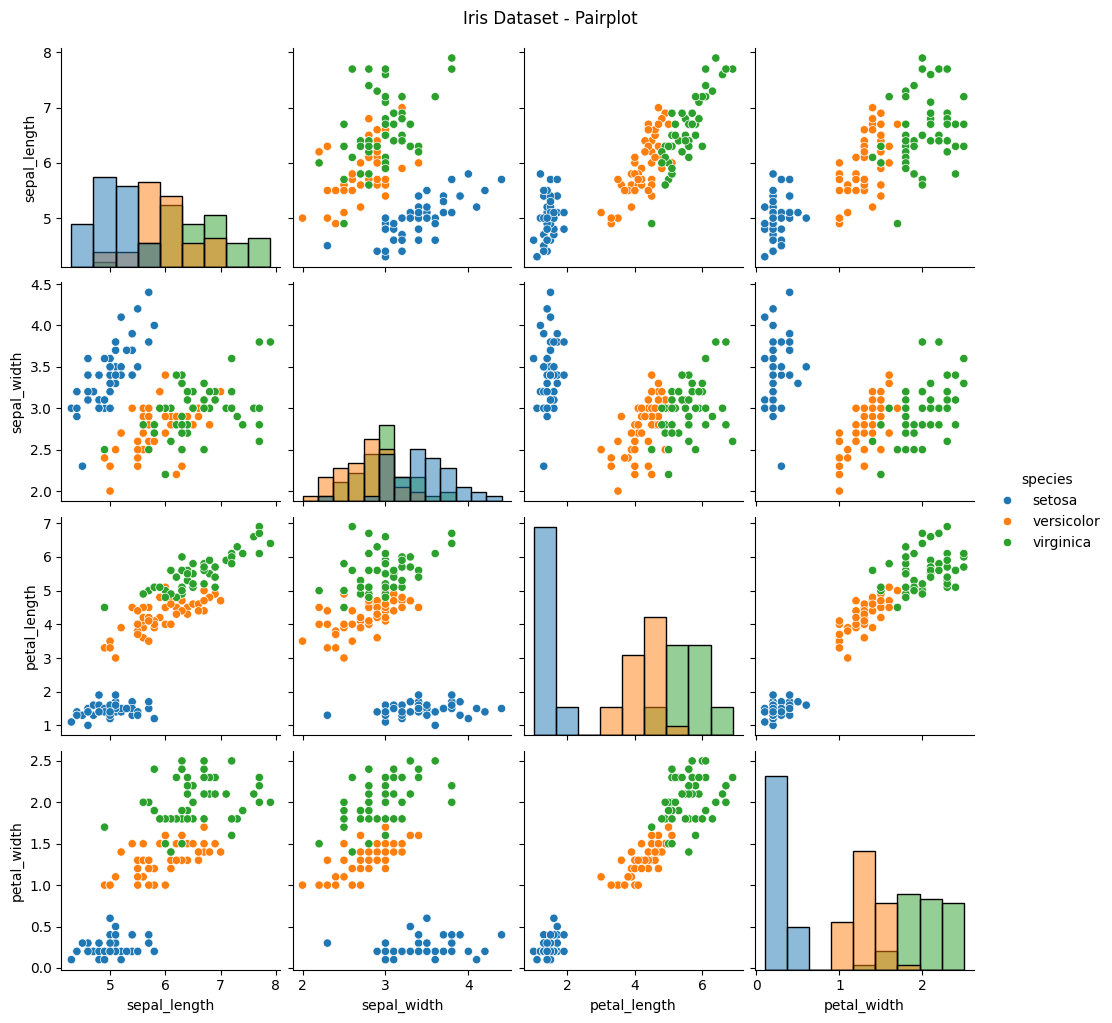

In [47]:
# Visualize relationships between features

sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

plt.suptitle("Iris Dataset - Pairplot", y=1.02)
plt.show()

Normalize the feature

In [48]:
# Separate input features and target variable

X = df.drop("species", axis=1)
y = df["species"]

print("Input Features (X):")
print(X.head())

print("\nTarget Variable (y):")
print(y.head())

Input Features (X):
   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2

Target Variable (y):
0    setosa
1    setosa
2    setosa
3    setosa
4    setosa
Name: species, dtype: object


Train-Test Split.

In [49]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data: (120, 4)
Testing data: (30, 4)

Training labels: (120,)
Testing labels: (30,)


Feature Scaling and Normalization.

In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data
X_test_scaled = scaler.transform(X_test)

print("Original values:")
print(X_train.head())

print("\nScaled values:")
print(X_train_scaled[:5])

Original values:
     sepal_length  sepal_width  petal_length  petal_width
8             4.4          2.9           1.4          0.2
106           4.9          2.5           4.5          1.7
76            6.8          2.8           4.8          1.4
9             4.9          3.1           1.5          0.1
89            5.5          2.5           4.0          1.3

Scaled values:
[[-1.72156775 -0.33210111 -1.34572231 -1.32327558]
 [-1.12449223 -1.22765467  0.41450518  0.6517626 ]
 [ 1.14439475 -0.5559895   0.58484978  0.25675496]
 [-1.12449223  0.11567567 -1.28894078 -1.45494479]
 [-0.40800161 -1.22765467  0.13059752  0.12508575]]


Model Training.

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Create Logistic Regression model
log_model = LogisticRegression(max_iter=1000)

# Create Decision Tree model
tree_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

print("Both models created successfully!")

Both models created successfully!


In [52]:
# Train Logistic Regression
log_model.fit(X_train_scaled, y_train)

# Train Decision Tree
tree_model.fit(X_train_scaled, y_train)

print("Both models trained successfully!")

Both models trained successfully!


In [53]:
log_model.fit(X_train_scaled, y_train)
tree_model.fit(X_train_scaled, y_train)

print("Both models trained successfully!")

Both models trained successfully!


Predictions.

In [54]:
log_predictions = log_model.predict(X_test_scaled)

tree_predictions = tree_model.predict(X_test_scaled)

print("Logistic Regression Predictions:")
print(log_predictions[:10])

print("\nDecision Tree Predictions:")
print(tree_predictions[:10])

Logistic Regression Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']

Decision Tree Predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor']


In [55]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Logistic Regression": log_predictions,
    "Decision Tree": tree_predictions
})

print(comparison.head(10))

       Actual Logistic Regression Decision Tree
0      setosa              setosa        setosa
1   virginica           virginica     virginica
2  versicolor          versicolor    versicolor
3  versicolor          versicolor    versicolor
4      setosa              setosa        setosa
5  versicolor          versicolor    versicolor
6      setosa              setosa        setosa
7      setosa              setosa        setosa
8   virginica           virginica     virginica
9  versicolor          versicolor    versicolor


In [56]:
models = {
    "Logistic Regression": log_model,
    "Decision Tree": tree_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test_scaled)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="macro"),
        "Recall": recall_score(y_test, predictions, average="macro"),
        "F1-Score": f1_score(y_test, predictions, average="macro")
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression     0.933      0.933   0.933     0.933
1        Decision Tree     0.967      0.970   0.967     0.967


In [57]:
for name, model in models.items():
    predictions = model.predict(X_test_scaled)

    print(f"\n{name}")
    print(classification_report(y_test, predictions))


Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



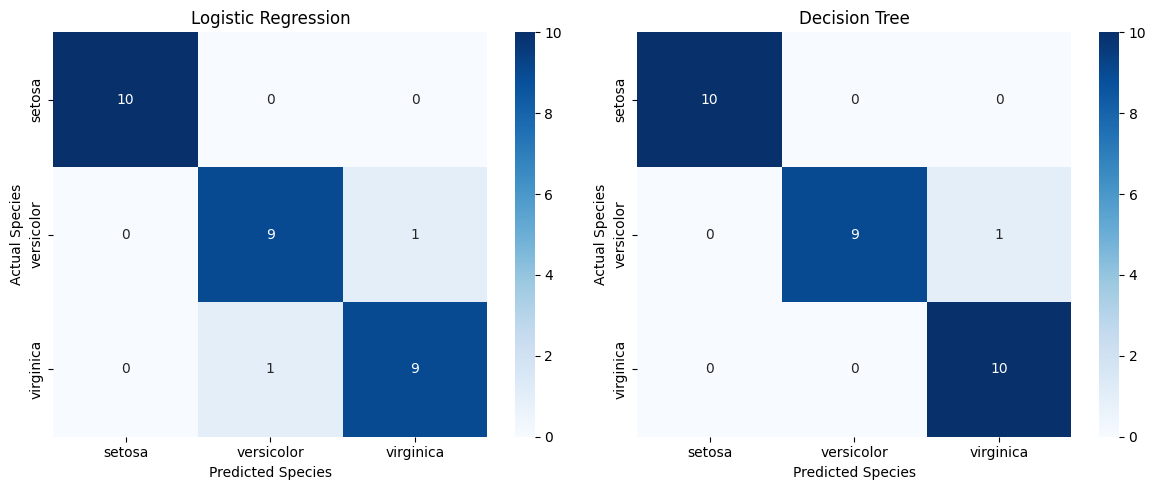

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, model) in zip(axes, models.items()):
    predictions = model.predict(X_test_scaled)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=model.classes_
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=model.classes_,
        yticklabels=model.classes_,
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Species")
    ax.set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

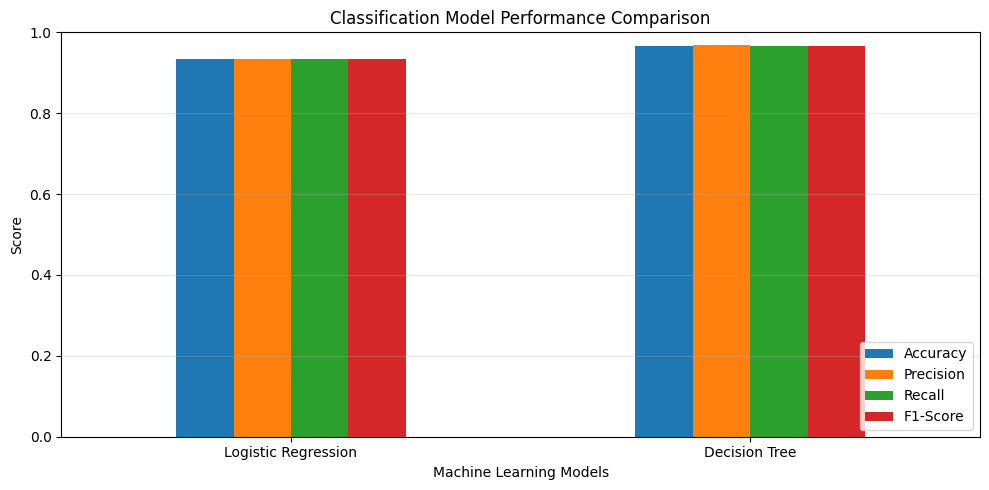

In [59]:
results_df.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("Classification Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [60]:
from sklearn.inspection import DecisionBoundaryDisplay

features_2d = ["petal_length", "petal_width"]

X_2d = df[features_2d]
y_2d = df["species"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.20,
    random_state=42,
    stratify=y_2d
)

scaler_2d = StandardScaler()

X2_train_scaled = scaler_2d.fit_transform(X2_train)

print("2D dataset prepared successfully!")
print("Training shape:", X2_train_scaled.shape)

2D dataset prepared successfully!
Training shape: (120, 2)


In [61]:
models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    )
}

for name, model in models_2d.items():
    model.fit(X2_train_scaled, y2_train)

print("Both 2D models trained successfully!")

Both 2D models trained successfully!


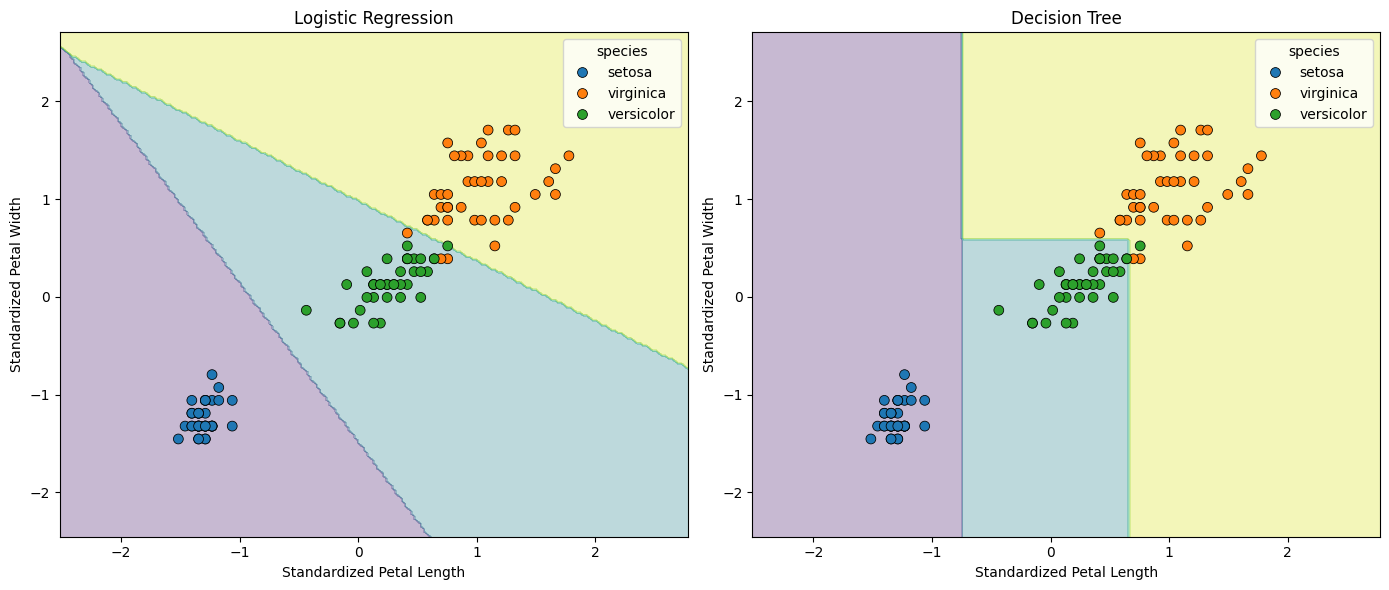

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, (name, model) in zip(axes, models_2d.items()):

    DecisionBoundaryDisplay.from_estimator(
        model,
        X2_train_scaled,
        response_method="predict",
        ax=ax,
        alpha=0.3,
        grid_resolution=200
    )

    sns.scatterplot(
        x=X2_train_scaled[:, 0],
        y=X2_train_scaled[:, 1],
        hue=y2_train,
        ax=ax,
        s=50,
        edgecolor="black"
    )

    ax.set_title(name)
    ax.set_xlabel("Standardized Petal Length")
    ax.set_ylabel("Standardized Petal Width")

plt.tight_layout()
plt.show()


## Conclusion

In this project, a multi-class classification benchmark was performed using the Iris dataset.

Two machine learning algorithms, Logistic Regression and Decision Tree, were trained and evaluated using an 80:20 train-test split.

The models were evaluated using accuracy, precision, recall, F1-score, classification reports, and confusion matrices.

**Results:**
- Logistic Regression achieved 93.3% accuracy.
- Decision Tree achieved 96.7% accuracy.

The Decision Tree model performed slightly better on the test dataset.

Exploratory data analysis, feature scaling, model comparison, confusion matrix heatmaps, and decision boundary visualizations were also performed.

This project helped demonstrate the practical workflow of building and evaluating multi-class machine learning classification models.